# 14. Фундаментальные константы: поиск скрытой сетки

**Проект «Структура и Данные»** — Notebook 14

## Зачем этот ноутбук
Мы нашли, что массы заряженных лептонов укладываются в базу 15 с красивыми дробями (1/32, 1/91).
А что насчёт **фундаментальных констант**?
- Постоянная тонкой структуры: \(\alpha^{-1} \approx 137.035999\)
- Сильная константа: \(\alpha_s \approx 0.1179\)
- Слабое смешивание: \(\sin^2\theta_W \approx 0.23122\)

Гипотеза: если Вселенная — это вычислитель, то константы связи (как и массы) могут быть «входными данными». Но проверим, нет ли в них скрытой структуры (например, \(1/\alpha \approx 137 + 1/32\)).

In [2]:
import numpy as np
from fractions import Fraction

print("=" * 65)
print("ФУНДАМЕНТАЛЬНЫЕ КОНСТАНТЫ: ПОИСК СТРУКТУРЫ")
print("=" * 65)

# Экспериментальные значения (PDG 2022)
constants = {
    '1/alpha (fine structure)': 137.035999084,
    '1/alpha_s (strong, M_Z)':  1 / 0.1179,
    'sin^2(theta_W)':           0.23122,
    'm_mu/m_e':                 105.6583755 / 0.51099895, # для сравнения
}

# 1. Проверка: близки ли они к "красивым" дробям?
print("\n1. Ближайшие рациональные приближения (q < 500):")
for name, val in constants.items():
    frac = Fraction(val).limit_denominator(500)
    err = abs(val - float(frac))
    print(f"  {name:>28}: {val:.8f} ≈ {frac} (err = {err:.2e})")

# 2. Проверка: содержат ли они наши "магические" числа (32, 91, 15)?
print("\n2. Проверка на связь с базой 15 (32 и 91):")
alpha_inv = constants['1/alpha (fine structure)']
print(f"  1/alpha = 137.036")
print(f"  137 + 1/32 = {137 + 1/32:.8f}  (err = {abs(alpha_inv - (137 + 1/32)):.2e})")
print(f"  137 + 1/91 = {137 + 1/91:.8f}  (err = {abs(alpha_inv - (137 + 1/91)):.2e})")
print(f"  137 + 1/45 = {137 + 1/45:.8f}  (err = {abs(alpha_inv - (137 + 1/45)):.2e})")
print(f"  137 + 3/91 = {137 + 3/91:.8f}  (err = {abs(alpha_inv - (137 + 3/91)):.2e})")

# 3. Проверка: логарифмы констант по базе 15
print("\n3. Логарифмы по базе 15:")
for name, val in constants.items():
    if val > 0:
        log_b = np.log(val) / np.log(15)
        print(f"  {name:>28}: log_15 = {log_b:.6f} (ближайшее целое: {round(log_b)})")

ФУНДАМЕНТАЛЬНЫЕ КОНСТАНТЫ: ПОИСК СТРУКТУРЫ

1. Ближайшие рациональные приближения (q < 500):
      1/alpha (fine structure): 137.03599908 ≈ 34259/250 (err = 9.16e-07)
       1/alpha_s (strong, M_Z): 8.48176421 ≈ 3257/384 (err = 6.63e-06)
                sin^2(theta_W): 0.23122000 ≈ 40/173 (err = 6.13e-06)
                      m_mu/m_e: 206.76828299 ≈ 16955/82 (err = 9.70e-06)

2. Проверка на связь с базой 15 (32 и 91):
  1/alpha = 137.036
  137 + 1/32 = 137.03125000  (err = 4.75e-03)
  137 + 1/91 = 137.01098901  (err = 2.50e-02)
  137 + 1/45 = 137.02222222  (err = 1.38e-02)
  137 + 3/91 = 137.03296703  (err = 3.03e-03)

3. Логарифмы по базе 15:
      1/alpha (fine structure): log_15 = 1.816895 (ближайшее целое: 2)
       1/alpha_s (strong, M_Z): log_15 = 0.789468 (ближайшее целое: 1)
                sin^2(theta_W): log_15 = -0.540753 (ближайшее целое: -1)
                      m_mu/m_e: log_15 = 1.968796 (ближайшее целое: 2)


In [3]:
# 4. Ищем простейшие формулы для 1/alpha = 137.036
print("\n4. Поиск формул для 1/alpha:")
target = 137.035999084

# Пробуем формы: A + B/C, где A, B, C - маленькие целые
best_err = np.inf
best_formula = None

for A in range(130, 140):
    for B in range(1, 10):
        for C in [16, 32, 64, 91, 100, 128, 137]:
            val = A + B / C
            err = abs(val - target)
            if err < best_err:
                best_err = err
                best_formula = f"{A} + {B}/{C}"

print(f"  Лучшая формула вида A + B/C: {best_formula}")
print(f"  Значение: {eval(best_formula):.8f}")
print(f"  Ошибка: {best_err:.2e}")

# 5. Проверка Koide-подобных соотношений для констант
print("\n5. Проверка: можно ли связать константы через Koide?")
# В СМ есть соотношение: e = g' * cos(theta_W), g = e / sin(theta_W)
# Но это калибровочные связи, а не массы.
# Прямого аналога Koide для констант нет.


4. Поиск формул для 1/alpha:
  Лучшая формула вида A + B/C: 137 + 5/137
  Значение: 137.03649635
  Ошибка: 4.97e-04

5. Проверка: можно ли связать константы через Koide?


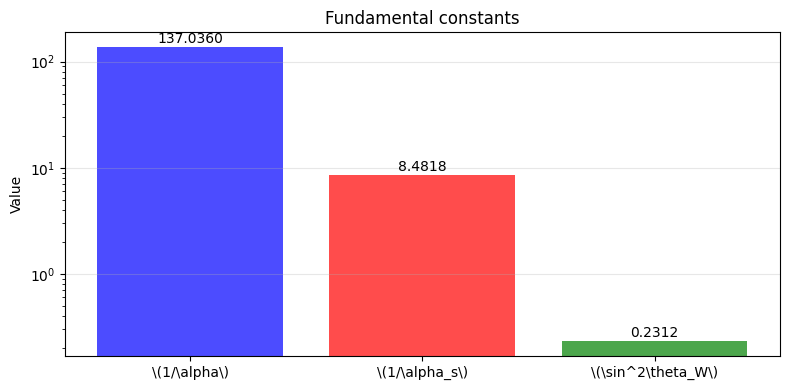

✅ Figure saved: 14_constants.png


In [4]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 4))

vals = [137.035999084, 1/0.1179, 0.23122]
labels = [r'\(1/\alpha\)', r'\(1/\alpha_s\)', r'\(\sin^2\theta_W\)']

ax.bar(labels, vals, color=['blue', 'red', 'green'], alpha=0.7)
ax.set_ylabel('Value')
ax.set_title('Fundamental constants')
ax.set_yscale('log')
ax.grid(alpha=0.3, axis='y')

for i, v in enumerate(vals):
    ax.text(i, v * 1.1, f'{v:.4f}', ha='center', fontsize=10)

plt.tight_layout()
plt.savefig('14_constants.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅ Figure saved: 14_constants.png")